In [53]:
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()

print(PROJECT_ROOT)

C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh


In [1]:
battery_ids = ["B0005", "B0006", "B0007", "B0018"]

lobo_folds = {}

for test_battery in battery_ids:
    train_batteries = [
        battery_id
        for battery_id in battery_ids
        if battery_id != test_battery
    ]

    lobo_folds[test_battery] = {
        "train": train_batteries,
        "test": test_battery
    }

for test_battery, fold in lobo_folds.items():
    print(
        f"Test: {fold['test']} | "
        f"Train: {fold['train']}"
    )

Test: B0005 | Train: ['B0006', 'B0007', 'B0018']
Test: B0006 | Train: ['B0005', 'B0007', 'B0018']
Test: B0007 | Train: ['B0005', 'B0006', 'B0018']
Test: B0018 | Train: ['B0005', 'B0006', 'B0007']


In [2]:
from pathlib import Path

import numpy as np
from scipy.io import loadmat

PROJECT_ROOT = Path("..").resolve()

CONTEXT_LENGTH = 64
PREDICTION_LENGTH = 16

battery_ids = ["B0005", "B0006", "B0007", "B0018"]

soh_data = {}

for battery_id in battery_ids:
    mat = loadmat(
        PROJECT_ROOT / "data" / "raw" / f"{battery_id}.mat",
        simplify_cells=True
    )

    cycles = mat[battery_id]["cycle"]

    capacities = np.array([
        cycle["data"]["Capacity"]
        for cycle in cycles
        if cycle["type"] == "discharge"
    ], dtype=float)

    soh_data[battery_id] = capacities / capacities[0]

    print(
        f"{battery_id}: "
        f"{len(soh_data[battery_id])} cycles | "
        f"SOH {soh_data[battery_id][0]:.4f}"
        f" → {soh_data[battery_id][-1]:.4f}"
    )

B0005: 168 cycles | SOH 1.0000 → 0.7138
B0006: 168 cycles | SOH 1.0000 → 0.5825
B0007: 168 cycles | SOH 1.0000 → 0.7575
B0018: 132 cycles | SOH 1.0000 → 0.7229


In [4]:
def make_windows(series, context_length=64, prediction_length=16):
    X = []
    y = []

    total_length = context_length + prediction_length

    for start in range(len(series) - total_length + 1):
        X.append(series[start:start + context_length])
        y.append(series[start + context_length:start + total_length])

    return np.array(X), np.array(y)

In [5]:
lobo_windows = {}

for test_battery, fold in lobo_folds.items():

    train_X_list = []
    train_y_list = []

    for train_battery in fold["train"]:
        X, y = make_windows(
            soh_data[train_battery],
            CONTEXT_LENGTH,
            PREDICTION_LENGTH
        )

        train_X_list.append(X)
        train_y_list.append(y)

    train_X = np.concatenate(train_X_list, axis=0)
    train_y = np.concatenate(train_y_list, axis=0)

    test_X, test_y = make_windows(
        soh_data[test_battery],
        CONTEXT_LENGTH,
        PREDICTION_LENGTH
    )

    lobo_windows[test_battery] = {
        "train_X": train_X,
        "train_y": train_y,
        "test_X": test_X,
        "test_y": test_y
    }

    print(
        f"Held-out {test_battery} | "
        f"Train {train_X.shape} / {train_y.shape} | "
        f"Test {test_X.shape} / {test_y.shape}"
    )

Held-out B0005 | Train (231, 64) / (231, 16) | Test (89, 64) / (89, 16)
Held-out B0006 | Train (231, 64) / (231, 16) | Test (89, 64) / (89, 16)
Held-out B0007 | Train (231, 64) / (231, 16) | Test (89, 64) / (89, 16)
Held-out B0018 | Train (267, 64) / (267, 16) | Test (53, 64) / (53, 16)


In [7]:
import torch
from chronos import ChronosPipeline

pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-base",
    device_map="xpu",
    dtype=torch.bfloat16,
)

config = pipeline.model.config

print("context_length   :", config.context_length)
print("prediction_length:", config.prediction_length)
print("n_tokens         :", config.n_tokens)
print("n_special_tokens :", config.n_special_tokens)
print("use_eos_token    :", config.use_eos_token)
print("model_type       :", config.model_type)
print("tokenizer        :", config.tokenizer_class)
print("tokenizer kwargs :", config.tokenizer_kwargs)

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

context_length   : 512
prediction_length: 64
n_tokens         : 4096
n_special_tokens : 2
use_eos_token    : True
model_type       : seq2seq
tokenizer        : MeanScaleUniformBins
tokenizer kwargs : {'low_limit': -15.0, 'high_limit': 15.0}


In [8]:
from dataclasses import replace

train_config = replace(
    config,
    context_length=CONTEXT_LENGTH,
    prediction_length=PREDICTION_LENGTH
)

train_tokenizer = train_config.create_tokenizer()

print("context_length   :", train_config.context_length)
print("prediction_length:", train_config.prediction_length)
print("tokenizer        :", train_config.tokenizer_class)
print("tokenizer kwargs :", train_config.tokenizer_kwargs)

context_length   : 64
prediction_length: 16
tokenizer        : MeanScaleUniformBins
tokenizer kwargs : {'low_limit': -15.0, 'high_limit': 15.0}


In [10]:
fold_data = lobo_windows["B0005"]

context_tensor = torch.tensor(
    fold_data["train_X"][0:1],
    dtype=torch.float32
)

label_tensor = torch.tensor(
    fold_data["train_y"][0:1],
    dtype=torch.float32
)

input_ids, attention_mask, scale = (
    train_tokenizer.context_input_transform(
        context_tensor
    )
)

label_ids, label_mask = (
    train_tokenizer.label_input_transform(
        label_tensor,
        scale
    )
)

print("raw context :", context_tensor.shape)
print("raw target  :", label_tensor.shape)

print("input_ids   :", input_ids.shape)
print("labels      :", label_ids.shape)

print("scale       :", scale)

print("context EOS :", input_ids[0, -1].item())
print("label EOS   :", label_ids[0, -1].item())

print("input token range:",
      input_ids.min().item(),
      input_ids.max().item())

print("label token range:",
      label_ids.min().item(),
      label_ids.max().item())

raw context : torch.Size([1, 64])
raw target  : torch.Size([1, 16])
input_ids   : torch.Size([1, 65])
labels      : torch.Size([1, 17])
scale       : tensor([0.8991])
context EOS : 1
label EOS   : 1
input token range: 1 2201
label token range: 1 2167


In [13]:
model = pipeline.model.model
device = next(model.parameters()).device

# label_mask=False인 위치는 CE loss에서 무시하도록 -100 처리
labels = label_ids.clone()
labels[~label_mask] = -100

with torch.no_grad():
    outputs = model(
        input_ids=input_ids.to(device),
        attention_mask=attention_mask.to(device),
        labels=labels.to(device),
    )

print("device :", device)
print("loss   :", outputs.loss.item())
print("logits :", outputs.logits.shape)

device : xpu:0
loss   : 2.328125
logits : torch.Size([1, 17, 4096])


In [14]:
for name, module in model.named_modules():
    if name.endswith(".q") or name.endswith(".v"):
        print(name, "->", type(module).__name__)

encoder.block.0.layer.0.SelfAttention.q -> Linear
encoder.block.0.layer.0.SelfAttention.v -> Linear
encoder.block.1.layer.0.SelfAttention.q -> Linear
encoder.block.1.layer.0.SelfAttention.v -> Linear
encoder.block.2.layer.0.SelfAttention.q -> Linear
encoder.block.2.layer.0.SelfAttention.v -> Linear
encoder.block.3.layer.0.SelfAttention.q -> Linear
encoder.block.3.layer.0.SelfAttention.v -> Linear
encoder.block.4.layer.0.SelfAttention.q -> Linear
encoder.block.4.layer.0.SelfAttention.v -> Linear
encoder.block.5.layer.0.SelfAttention.q -> Linear
encoder.block.5.layer.0.SelfAttention.v -> Linear
encoder.block.6.layer.0.SelfAttention.q -> Linear
encoder.block.6.layer.0.SelfAttention.v -> Linear
encoder.block.7.layer.0.SelfAttention.q -> Linear
encoder.block.7.layer.0.SelfAttention.v -> Linear
encoder.block.8.layer.0.SelfAttention.q -> Linear
encoder.block.8.layer.0.SelfAttention.v -> Linear
encoder.block.9.layer.0.SelfAttention.q -> Linear
encoder.block.9.layer.0.SelfAttention.v -> Linear


In [16]:
from peft import (
    LoraConfig,
    TaskType,
    get_peft_model
)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q", "v"],
    bias="none",
    task_type=TaskType.SEQ_2_SEQ_LM,
)

lora_model = get_peft_model(
    model,
    lora_config
)

lora_model.print_trainable_parameters()

trainable params: 884,736 || all params: 202,259,712 || trainable%: 0.4374


In [21]:
from torch.utils.data import TensorDataset, DataLoader

fold_data = lobo_windows["B0005"]

train_context = torch.tensor(
    fold_data["train_X"],
    dtype=torch.float32
)

train_target = torch.tensor(
    fold_data["train_y"],
    dtype=torch.float32
)

train_input_ids, train_attention_mask, train_scale = (
    train_tokenizer.context_input_transform(
        train_context
    )
)

train_label_ids, train_label_mask = (
    train_tokenizer.label_input_transform(
        train_target,
        train_scale
    )
)

train_labels = train_label_ids.clone()
train_labels[~train_label_mask] = -100

print("input_ids:", train_input_ids.shape)
print("attention :", train_attention_mask.shape)
print("labels    :", train_labels.shape)

input_ids: torch.Size([231, 65])
attention : torch.Size([231, 65])
labels    : torch.Size([231, 17])


In [22]:
BATCH_SIZE = 16

train_dataset = TensorDataset(
    train_input_ids,
    train_attention_mask,
    train_labels
)

generator = torch.Generator()
generator.manual_seed(42)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0
)

print("batches per epoch:", len(train_loader))

batches per epoch: 15


In [23]:
optimizer = torch.optim.AdamW(
    (p for p in lora_model.parameters() if p.requires_grad),
    lr=1e-4,
    weight_decay=0.0
)

lora_model.train()

epoch_loss = 0.0

for step, batch in enumerate(train_loader, start=1):
    input_ids_batch, attention_batch, labels_batch = batch

    input_ids_batch = input_ids_batch.to(device)
    attention_batch = attention_batch.to(device)
    labels_batch = labels_batch.to(device)

    optimizer.zero_grad(set_to_none=True)

    outputs = lora_model(
        input_ids=input_ids_batch,
        attention_mask=attention_batch,
        labels=labels_batch
    )

    loss = outputs.loss
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        lora_model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    epoch_loss += loss.item()

    print(
        f"Step {step:02d}/{len(train_loader)} | "
        f"Loss {loss.item():.4f}"
    )

mean_loss = epoch_loss / len(train_loader)

print(f"\nEpoch 1 mean loss: {mean_loss:.4f}")

Step 01/15 | Loss 2.1406
Step 02/15 | Loss 2.2031
Step 03/15 | Loss 2.2188
Step 04/15 | Loss 2.2031
Step 05/15 | Loss 2.3594
Step 06/15 | Loss 2.1875
Step 07/15 | Loss 2.2656
Step 08/15 | Loss 2.2500
Step 09/15 | Loss 2.3750
Step 10/15 | Loss 2.2969
Step 11/15 | Loss 2.2969
Step 12/15 | Loss 2.1875
Step 13/15 | Loss 2.1562
Step 14/15 | Loss 2.2500
Step 15/15 | Loss 2.2500

Epoch 1 mean loss: 2.2427


In [24]:
from chronos import ChronosPipeline
from peft import LoraConfig, TaskType, get_peft_model

def create_fresh_lora_model():
    pipeline = ChronosPipeline.from_pretrained(
        "amazon/chronos-t5-base",
        device_map="xpu",
        torch_dtype=torch.bfloat16,
    )

    base_model = pipeline.model.model

    lora_config = LoraConfig(
        r=8,
        lora_alpha=16,
        lora_dropout=0.05,
        target_modules=["q", "v"],
        bias="none",
        task_type=TaskType.SEQ_2_SEQ_LM,
    )

    lora_model = get_peft_model(
        base_model,
        lora_config
    )

    return pipeline, lora_model

In [25]:
del lora_model
del model
del pipeline

torch.xpu.empty_cache()

pipeline, lora_model = create_fresh_lora_model()

lora_model.print_trainable_parameters()

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

trainable params: 884,736 || all params: 202,259,712 || trainable%: 0.4374


In [26]:
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

SEED = 42
EPOCHS = 10
BATCH_SIZE = 16
LEARNING_RATE = 1e-4

torch.manual_seed(SEED)

fold_data = lobo_windows["B0005"]

train_context = torch.tensor(
    fold_data["train_X"],
    dtype=torch.float32
)

train_target = torch.tensor(
    fold_data["train_y"],
    dtype=torch.float32
)

train_input_ids, train_attention_mask, train_scale = (
    train_tokenizer.context_input_transform(train_context)
)

train_label_ids, train_label_mask = (
    train_tokenizer.label_input_transform(
        train_target,
        train_scale
    )
)

train_labels = train_label_ids.clone()
train_labels[~train_label_mask] = -100

train_dataset = TensorDataset(
    train_input_ids,
    train_attention_mask,
    train_labels
)

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0
)

print("Training windows :", len(train_dataset))
print("Batches / epoch  :", len(train_loader))

Training windows : 231
Batches / epoch  : 15


In [27]:
device = next(lora_model.parameters()).device

trainable_params = [
    p for p in lora_model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=0.0
)

epoch_losses = []

for epoch in range(1, EPOCHS + 1):

    lora_model.train()

    total_loss = 0.0
    total_samples = 0

    for batch in train_loader:
        input_ids_batch, attention_batch, labels_batch = batch

        input_ids_batch = input_ids_batch.to(device)
        attention_batch = attention_batch.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = lora_model(
            input_ids=input_ids_batch,
            attention_mask=attention_batch,
            labels=labels_batch
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )

        optimizer.step()

        batch_size = input_ids_batch.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    mean_loss = total_loss / total_samples
    epoch_losses.append(mean_loss)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Mean CE Loss = {mean_loss:.4f}"
    )

Epoch 01/10 | Mean CE Loss = 2.2562
Epoch 02/10 | Mean CE Loss = 2.2380
Epoch 03/10 | Mean CE Loss = 2.2054
Epoch 04/10 | Mean CE Loss = 2.1514
Epoch 05/10 | Mean CE Loss = 2.0887
Epoch 06/10 | Mean CE Loss = 1.9867
Epoch 07/10 | Mean CE Loss = 1.8512
Epoch 08/10 | Mean CE Loss = 1.6633
Epoch 09/10 | Mean CE Loss = 1.5308
Epoch 10/10 | Mean CE Loss = 1.4547


In [28]:
lora_model.eval()

# Chronos pipeline이 학습된 LoRA 모델을 사용하도록 연결
pipeline.model.model = lora_model

print(type(pipeline.model.model))

<class 'peft.peft_model.PeftModelForSeq2SeqLM'>


In [31]:
test_X = fold_data["test_X"]
test_y = fold_data["test_y"]

NUM_SAMPLES = 20
INFERENCE_BATCH_SIZE = 16

torch.manual_seed(42)

all_preds = []

for start in range(0, len(test_X), INFERENCE_BATCH_SIZE):
    context_batch = torch.tensor(
        test_X[start:start + INFERENCE_BATCH_SIZE],
        dtype=torch.float32
    )

    with torch.no_grad():
        forecast_batch = pipeline.predict(
            context_batch,
            prediction_length=PREDICTION_LENGTH,
            num_samples=NUM_SAMPLES
        )

    median_batch = (
        forecast_batch
        .median(dim=1)
        .values
        .cpu()
        .numpy()
    )

    all_preds.append(median_batch)

    print(
        f"{min(start + INFERENCE_BATCH_SIZE, len(test_X))}"
        f"/{len(test_X)} done"
    )

lora_pred_B0005 = np.concatenate(
    all_preds,
    axis=0
)

print("prediction shape:", lora_pred_B0005.shape)

16/89 done
32/89 done
48/89 done
64/89 done
80/89 done
89/89 done
prediction shape: (89, 16)


In [32]:
lora_rmse_B0005 = np.sqrt(
    np.mean((test_y - lora_pred_B0005) ** 2)
)

lora_mae_B0005 = np.mean(
    np.abs(test_y - lora_pred_B0005)
)

print(f"LoRA B0005 RMSE: {lora_rmse_B0005:.6f}")
print(f"LoRA B0005 MAE : {lora_mae_B0005:.6f}")

LoRA B0005 RMSE: 0.011835
LoRA B0005 MAE : 0.008273


In [33]:
lora_results = {
    "B0005": {
        "rmse": lora_rmse_B0005,
        "mae": lora_mae_B0005
    }
}

lora_predictions = {
    "B0005": lora_pred_B0005
}

In [34]:
del lora_model
del pipeline

torch.xpu.empty_cache()

pipeline, lora_model = create_fresh_lora_model()

lora_model.print_trainable_parameters()

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

trainable params: 884,736 || all params: 202,259,712 || trainable%: 0.4374


In [39]:
fold_data = lobo_windows["B0006"]

print("Train:", fold_data["train_X"].shape)
print("Test :", fold_data["test_X"].shape)

Train: (231, 64)
Test : (89, 64)


In [40]:
fold_data = lobo_windows["B0006"]

train_context = torch.tensor(
    fold_data["train_X"],
    dtype=torch.float32
)

train_target = torch.tensor(
    fold_data["train_y"],
    dtype=torch.float32
)

train_input_ids, train_attention_mask, train_scale = (
    train_tokenizer.context_input_transform(train_context)
)

train_label_ids, train_label_mask = (
    train_tokenizer.label_input_transform(
        train_target,
        train_scale
    )
)

train_labels = train_label_ids.clone()
train_labels[~train_label_mask] = -100

train_dataset = TensorDataset(
    train_input_ids,
    train_attention_mask,
    train_labels
)

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0
)

print("Train windows:", len(train_dataset))
print("Batches:", len(train_loader))

Train windows: 231
Batches: 15


In [41]:
device = next(lora_model.parameters()).device

trainable_params = [
    p for p in lora_model.parameters()
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_params,
    lr=LEARNING_RATE,
    weight_decay=0.0
)

epoch_losses_B0006 = []

for epoch in range(1, EPOCHS + 1):
    lora_model.train()

    total_loss = 0.0
    total_samples = 0

    for batch in train_loader:
        input_ids_batch, attention_batch, labels_batch = batch

        input_ids_batch = input_ids_batch.to(device)
        attention_batch = attention_batch.to(device)
        labels_batch = labels_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = lora_model(
            input_ids=input_ids_batch,
            attention_mask=attention_batch,
            labels=labels_batch
        )

        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=1.0
        )

        optimizer.step()

        batch_size = input_ids_batch.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

    mean_loss = total_loss / total_samples
    epoch_losses_B0006.append(mean_loss)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Mean CE Loss = {mean_loss:.4f}"
    )

Epoch 01/10 | Mean CE Loss = 2.1770
Epoch 02/10 | Mean CE Loss = 2.1558
Epoch 03/10 | Mean CE Loss = 2.1296
Epoch 04/10 | Mean CE Loss = 2.0892
Epoch 05/10 | Mean CE Loss = 2.0040
Epoch 06/10 | Mean CE Loss = 1.8960
Epoch 07/10 | Mean CE Loss = 1.7525
Epoch 08/10 | Mean CE Loss = 1.5694
Epoch 09/10 | Mean CE Loss = 1.4613
Epoch 10/10 | Mean CE Loss = 1.3812


In [42]:
lora_model.eval()
pipeline.model.model = lora_model

In [43]:
test_X = fold_data["test_X"]
test_y = fold_data["test_y"]

torch.manual_seed(SEED)

all_preds = []

for start in range(0, len(test_X), INFERENCE_BATCH_SIZE):
    context_batch = torch.tensor(
        test_X[start:start + INFERENCE_BATCH_SIZE],
        dtype=torch.float32
    )

    with torch.no_grad():
        forecast_batch = pipeline.predict(
            context_batch,
            prediction_length=PREDICTION_LENGTH,
            num_samples=NUM_SAMPLES
        )

    median_batch = (
        forecast_batch
        .median(dim=1)
        .values
        .cpu()
        .numpy()
    )

    all_preds.append(median_batch)

lora_pred_B0006 = np.concatenate(all_preds, axis=0)

print("prediction shape:", lora_pred_B0006.shape)

prediction shape: (89, 16)


In [44]:
lora_rmse_B0006 = np.sqrt(
    np.mean((test_y - lora_pred_B0006) ** 2)
)

lora_mae_B0006 = np.mean(
    np.abs(test_y - lora_pred_B0006)
)

print(f"LoRA B0006 RMSE: {lora_rmse_B0006:.6f}")
print(f"LoRA B0006 MAE : {lora_mae_B0006:.6f}")

LoRA B0006 RMSE: 0.019555
LoRA B0006 MAE : 0.012205


In [45]:
lora_results["B0006"] = {
    "rmse": lora_rmse_B0006,
    "mae": lora_mae_B0006
}

lora_predictions["B0006"] = lora_pred_B0006

In [46]:
import gc

def run_lobo_fold(test_battery):
    print(f"\n{'='*60}")
    print(f"Held-out battery: {test_battery}")
    print(f"{'='*60}")

    # -------------------------
    # 1. Fresh Chronos + LoRA
    # -------------------------
    pipeline, lora_model = create_fresh_lora_model()

    device = next(lora_model.parameters()).device

    torch.manual_seed(SEED)

    if torch.xpu.is_available():
        torch.xpu.manual_seed_all(SEED)

    # -------------------------
    # 2. Fold data
    # -------------------------
    fold_data = lobo_windows[test_battery]

    train_context = torch.tensor(
        fold_data["train_X"],
        dtype=torch.float32
    )

    train_target = torch.tensor(
        fold_data["train_y"],
        dtype=torch.float32
    )

    test_X = fold_data["test_X"]
    test_y = fold_data["test_y"]

    print("Train windows:", train_context.shape[0])
    print("Test windows :", len(test_X))

    # -------------------------
    # 3. Chronos tokenization
    # -------------------------
    train_input_ids, train_attention_mask, train_scale = (
        train_tokenizer.context_input_transform(
            train_context
        )
    )

    train_label_ids, train_label_mask = (
        train_tokenizer.label_input_transform(
            train_target,
            train_scale
        )
    )

    train_labels = train_label_ids.clone()
    train_labels[~train_label_mask] = -100

    # -------------------------
    # 4. DataLoader
    # -------------------------
    train_dataset = TensorDataset(
        train_input_ids,
        train_attention_mask,
        train_labels
    )

    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    # -------------------------
    # 5. Optimizer
    # -------------------------
    trainable_params = [
        p for p in lora_model.parameters()
        if p.requires_grad
    ]

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=LEARNING_RATE,
        weight_decay=0.0
    )

    # -------------------------
    # 6. LoRA training
    # -------------------------
    epoch_losses = []

    for epoch in range(1, EPOCHS + 1):
        lora_model.train()

        total_loss = 0.0
        total_samples = 0

        for batch in train_loader:
            input_ids_batch, attention_batch, labels_batch = batch

            input_ids_batch = input_ids_batch.to(device)
            attention_batch = attention_batch.to(device)
            labels_batch = labels_batch.to(device)

            optimizer.zero_grad(set_to_none=True)

            outputs = lora_model(
                input_ids=input_ids_batch,
                attention_mask=attention_batch,
                labels=labels_batch
            )

            loss = outputs.loss
            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                trainable_params,
                max_norm=1.0
            )

            optimizer.step()

            batch_size = input_ids_batch.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

        mean_loss = total_loss / total_samples
        epoch_losses.append(mean_loss)

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"Mean CE Loss = {mean_loss:.4f}"
        )

    # -------------------------
    # 7. Held-out inference
    # -------------------------
    lora_model.eval()

    pipeline.model.model = lora_model

    torch.manual_seed(SEED)

    if torch.xpu.is_available():
        torch.xpu.manual_seed_all(SEED)

    all_preds = []

    for start in range(0, len(test_X), INFERENCE_BATCH_SIZE):
        context_batch = torch.tensor(
            test_X[start:start + INFERENCE_BATCH_SIZE],
            dtype=torch.float32
        )

        with torch.inference_mode():
            forecast_batch = pipeline.predict(
                context_batch,
                prediction_length=PREDICTION_LENGTH,
                num_samples=NUM_SAMPLES
            )

        median_batch = (
            forecast_batch
            .median(dim=1)
            .values
            .cpu()
            .numpy()
        )

        all_preds.append(median_batch)

    y_pred = np.concatenate(all_preds, axis=0)

    # -------------------------
    # 8. Metrics
    # -------------------------
    rmse = np.sqrt(
        np.mean((test_y - y_pred) ** 2)
    )

    mae = np.mean(
        np.abs(test_y - y_pred)
    )

    print()
    print(f"{test_battery} LoRA RMSE: {rmse:.6f}")
    print(f"{test_battery} LoRA MAE : {mae:.6f}")

    result = {
        "rmse": rmse,
        "mae": mae,
        "epoch_losses": epoch_losses,
        "prediction": y_pred
    }

    # -------------------------
    # 9. Memory cleanup
    # -------------------------
    del optimizer
    del lora_model
    del pipeline

    gc.collect()

    if torch.xpu.is_available():
        torch.xpu.empty_cache()

    return result

In [47]:
for battery_id in ["B0007", "B0018"]:
    result = run_lobo_fold(battery_id)

    lora_results[battery_id] = {
        "rmse": result["rmse"],
        "mae": result["mae"]
    }

    lora_predictions[battery_id] = result["prediction"]


Held-out battery: B0007


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Train windows: 231
Test windows : 89
Epoch 01/10 | Mean CE Loss = 2.2950
Epoch 02/10 | Mean CE Loss = 2.2833
Epoch 03/10 | Mean CE Loss = 2.2399
Epoch 04/10 | Mean CE Loss = 2.1837
Epoch 05/10 | Mean CE Loss = 2.1040
Epoch 06/10 | Mean CE Loss = 1.9973
Epoch 07/10 | Mean CE Loss = 1.8408
Epoch 08/10 | Mean CE Loss = 1.6378
Epoch 09/10 | Mean CE Loss = 1.5405
Epoch 10/10 | Mean CE Loss = 1.4763

B0007 LoRA RMSE: 0.009840
B0007 LoRA MAE : 0.006432

Held-out battery: B0018


Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

Train windows: 267
Test windows : 53
Epoch 01/10 | Mean CE Loss = 2.1807
Epoch 02/10 | Mean CE Loss = 2.1627
Epoch 03/10 | Mean CE Loss = 2.1156
Epoch 04/10 | Mean CE Loss = 2.0466
Epoch 05/10 | Mean CE Loss = 1.9342
Epoch 06/10 | Mean CE Loss = 1.8106
Epoch 07/10 | Mean CE Loss = 1.5856
Epoch 08/10 | Mean CE Loss = 1.4411
Epoch 09/10 | Mean CE Loss = 1.3907
Epoch 10/10 | Mean CE Loss = 1.3425

B0018 LoRA RMSE: 0.021315
B0018 LoRA MAE : 0.015628


In [48]:
import pandas as pd

comparison = pd.DataFrame({
    "Battery": ["B0005", "B0006", "B0007", "B0018"],
    "Last_RMSE": [0.022004, 0.024485, 0.017806, 0.022700],
    "Linear_RMSE": [0.019174, 0.026631, 0.016162, 0.030008],
    "ZeroShot_RMSE": [0.013641, 0.019418, 0.012504, 0.023311],
    "LoRA_RMSE": [0.011835, 0.019555, 0.009840, 0.021315],

    "Last_MAE": [0.018166, 0.019867, 0.014452, 0.018771],
    "Linear_MAE": [0.015175, 0.019419, 0.013084, 0.022639],
    "ZeroShot_MAE": [0.009533, 0.013335, 0.008332, 0.017199],
    "LoRA_MAE": [0.008273, 0.012205, 0.006432, 0.015628],
})

macro_row = {
    "Battery": "Macro",
    "Last_RMSE": comparison["Last_RMSE"].mean(),
    "Linear_RMSE": comparison["Linear_RMSE"].mean(),
    "ZeroShot_RMSE": comparison["ZeroShot_RMSE"].mean(),
    "LoRA_RMSE": comparison["LoRA_RMSE"].mean(),
    "Last_MAE": comparison["Last_MAE"].mean(),
    "Linear_MAE": comparison["Linear_MAE"].mean(),
    "ZeroShot_MAE": comparison["ZeroShot_MAE"].mean(),
    "LoRA_MAE": comparison["LoRA_MAE"].mean(),
}

comparison = pd.concat(
    [comparison, pd.DataFrame([macro_row])],
    ignore_index=True
)

comparison

,Battery,Last_RMSE,Linear_RMSE,ZeroShot_RMSE,LoRA_RMSE,Last_MAE,Linear_MAE,ZeroShot_MAE,LoRA_MAE
0,B0005,0.022004,0.019174,0.013641,0.011835,0.018166,0.015175,0.009533,0.008273
1,B0006,0.024485,0.026631,0.019418,0.019555,0.019867,0.019419,0.013335,0.012205
2,B0007,0.017806,0.016162,0.012504,0.009840,0.014452,0.013084,0.008332,0.006432
3,B0018,0.022700,0.030008,0.023311,0.021315,0.018771,0.022639,0.017199,0.015628
4,Macro,0.021749,0.022994,0.017219,0.015636,0.017814,0.017579,0.012100,0.010635


In [49]:
output_path = PROJECT_ROOT / "results" / "metrics" / "chronos_lobo_results.csv"

comparison.to_csv(
    output_path,
    index=False
)

print(output_path)

C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\results\metrics\chronos_lobo_results.csv


In [51]:
import matplotlib.pyplot as plt
import numpy as np

def plot_lora_all_batteries():
    battery_ids = ["B0005", "B0006", "B0007", "B0018"]

    fig, axes = plt.subplots(
        len(battery_ids),
        3,
        figsize=(18, 16)
    )

    for row, battery_id in enumerate(battery_ids):
        X = lobo_windows[battery_id]["test_X"]
        y = lobo_windows[battery_id]["test_y"]
        y_pred = lora_predictions[battery_id]

        window_indices = [0, len(X) // 2, len(X) - 1]

        for col, idx in enumerate(window_indices):
            ax = axes[row, col]

            context = X[idx]
            true_future = y[idx]
            pred_future = y_pred[idx]

            context_start = idx + 1
            context_end = idx + CONTEXT_LENGTH

            forecast_start = context_end + 1
            forecast_end = context_end + PREDICTION_LENGTH

            context_cycles = np.arange(
                context_start,
                context_end + 1
            )

            future_cycles = np.arange(
                forecast_start,
                forecast_end + 1
            )

            rmse = np.sqrt(
                np.mean((true_future - pred_future) ** 2)
            )
            mae = np.mean(
                np.abs(true_future - pred_future)
            )

            ax.plot(
                context_cycles,
                context,
                label="Context"
            )

            ax.plot(
                future_cycles,
                true_future,
                marker="o",
                label="True future"
            )

            ax.plot(
                future_cycles,
                pred_future,
                marker="x",
                label="LoRA prediction"
            )

            ax.axvline(
                context_end,
                linestyle="--",
                alpha=0.5
            )

            ax.set_title(
                f"{battery_id} | Window {idx+1}\n"
                f"{context_start}-{context_end} → "
                f"{forecast_start}-{forecast_end}\n"
                f"RMSE={rmse:.4f}, MAE={mae:.4f}"
            )

            ax.set_xlabel("Discharge cycle")
            ax.set_ylabel("SOH")
            ax.grid(alpha=0.3)

            if row == 0 and col == 0:
                ax.legend()

    plt.suptitle("LoRA Forecast Trajectories by Battery", fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

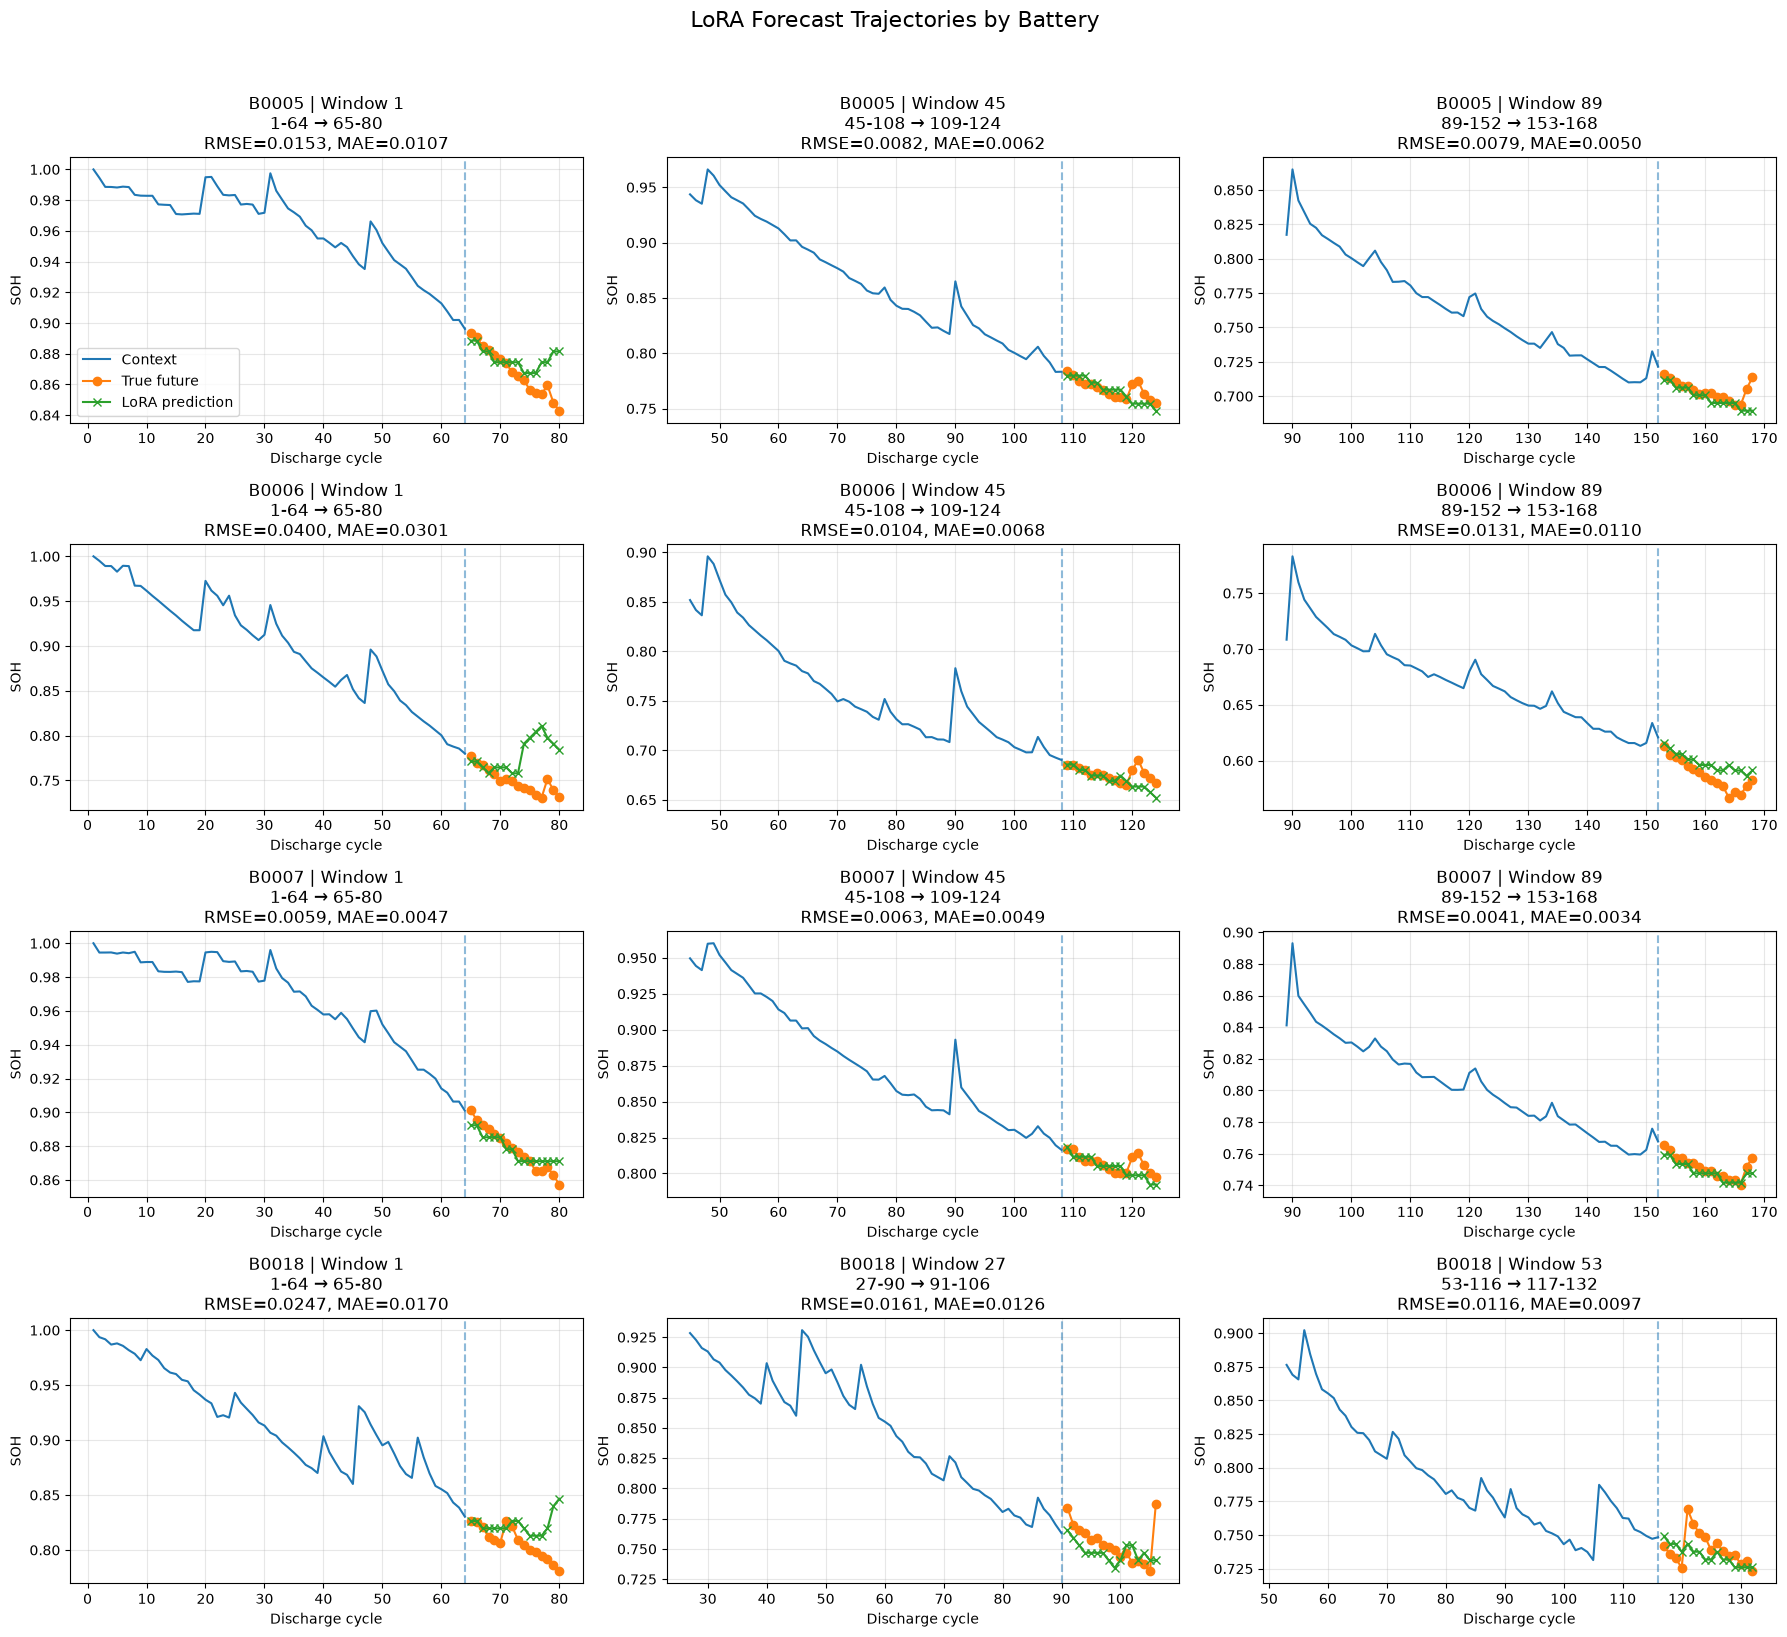

In [52]:
plot_lora_all_batteries()

In [54]:
zero_data = np.load(
    PROJECT_ROOT
    / "results"
    / "metrics"
    / "chronos_zeroshot_predictions.npz"
)

zeroshot_predictions = {
    battery_id: zero_data[battery_id]
    for battery_id in zero_data.files
}

for battery_id, pred in zeroshot_predictions.items():
    print(battery_id, pred.shape)

B0005 (89, 16)
B0006 (89, 16)
B0007 (89, 16)
B0018 (53, 16)


In [56]:
delta_rmse_data = {}

battery_ids = ["B0005", "B0006", "B0007", "B0018"]

for battery_id in battery_ids:
    y_true = lobo_windows[battery_id]["test_y"]

    zero_pred = zeroshot_predictions[battery_id]
    lora_pred = lora_predictions[battery_id]

    zero_window_rmse = np.sqrt(
        np.mean((y_true - zero_pred) ** 2, axis=1)
    )

    lora_window_rmse = np.sqrt(
        np.mean((y_true - lora_pred) ** 2, axis=1)
    )

    delta_rmse = zero_window_rmse - lora_window_rmse

    forecast_start_cycles = (
        np.arange(len(delta_rmse))
        + CONTEXT_LENGTH
        + 1
    )

    delta_rmse_data[battery_id] = {
        "forecast_start": forecast_start_cycles,
        "delta_rmse": delta_rmse,
        "zero_rmse": zero_window_rmse,
        "lora_rmse": lora_window_rmse,
    }

    print(
        battery_id,
        "mean delta RMSE:",
        delta_rmse.mean()
    )

B0005 mean delta RMSE: 0.0009355603186360416
B0006 mean delta RMSE: 0.0012619193734351806
B0007 mean delta RMSE: 0.002132338331475283
B0018 mean delta RMSE: 0.0012720187549171667


In [58]:
for battery_id in battery_ids:
    delta = delta_rmse_data[battery_id]["delta_rmse"]

    improved = np.sum(delta > 0)
    worsened = np.sum(delta < 0)
    tied = np.sum(np.isclose(delta, 0))

    print(f"\n[{battery_id}]")
    print(f"Improved windows : {improved}")
    print(f"Worsened windows : {worsened}")
    print(f"Tied windows     : {tied}")
    print(f"Improvement ratio: {improved / len(delta):.3f}")
    print(f"Mean delta RMSE  : {delta.mean():.6f}")


[B0005]
Improved windows : 52
Worsened windows : 37
Tied windows     : 0
Improvement ratio: 0.584
Mean delta RMSE  : 0.000936

[B0006]
Improved windows : 59
Worsened windows : 30
Tied windows     : 0
Improvement ratio: 0.663
Mean delta RMSE  : 0.001262

[B0007]
Improved windows : 68
Worsened windows : 21
Tied windows     : 0
Improvement ratio: 0.764
Mean delta RMSE  : 0.002132

[B0018]
Improved windows : 33
Worsened windows : 20
Tied windows     : 0
Improvement ratio: 0.623
Mean delta RMSE  : 0.001272


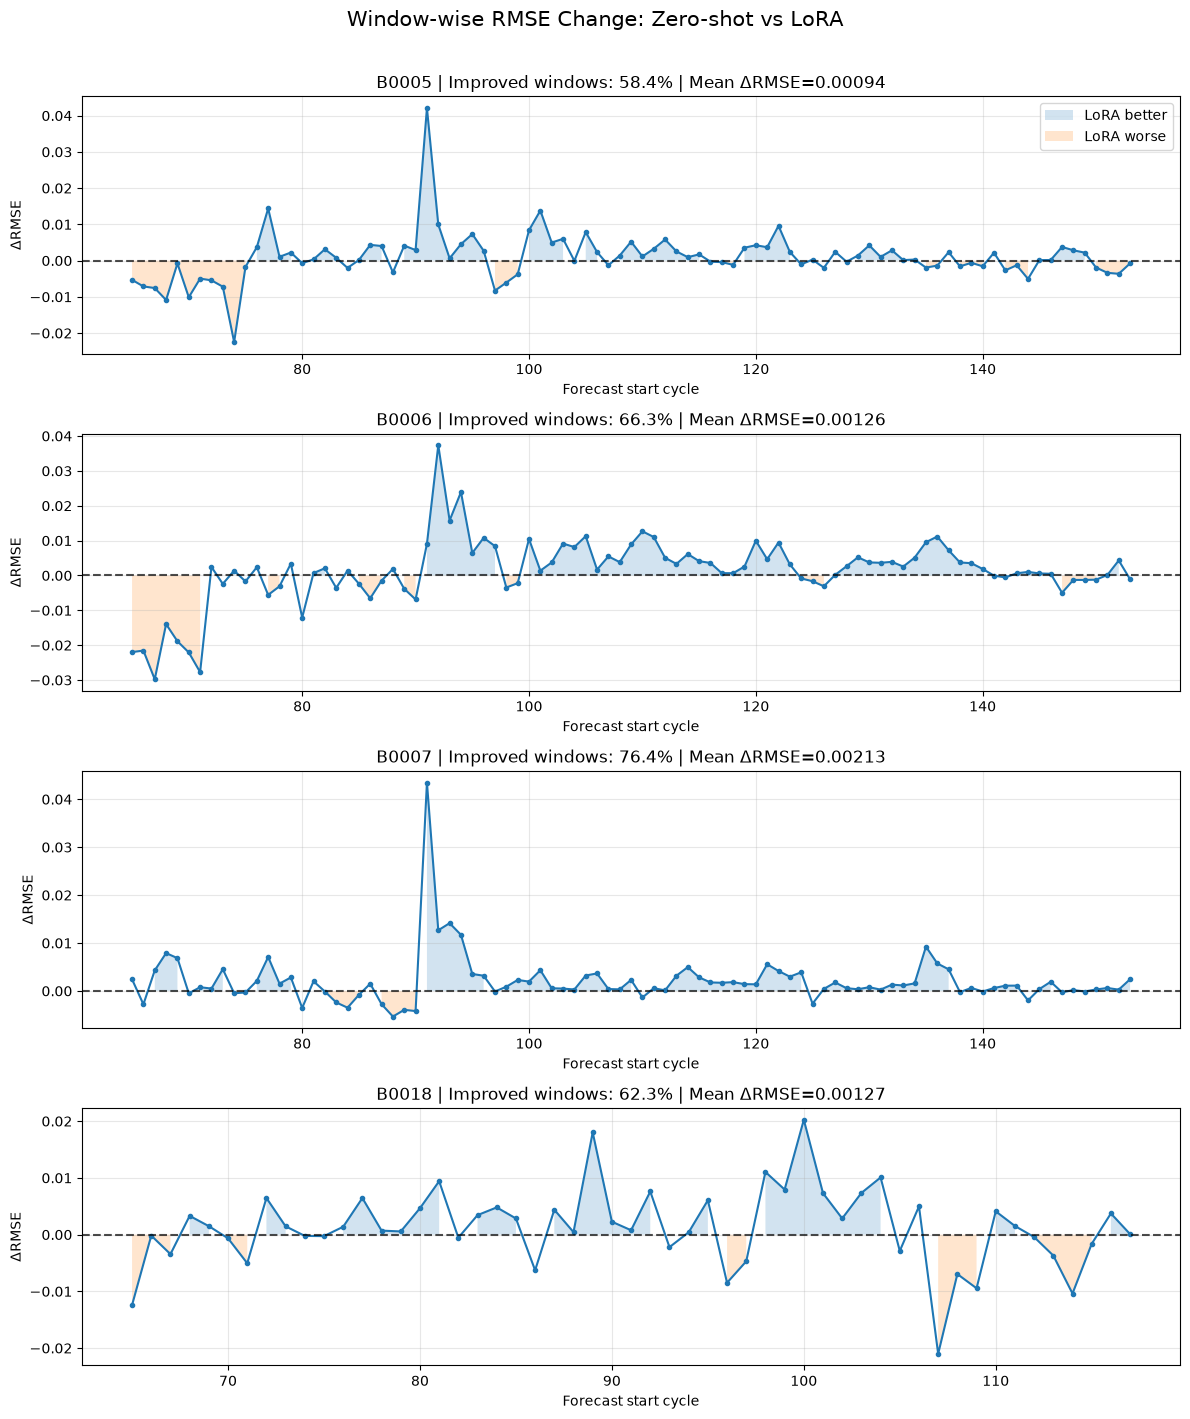

In [59]:
fig, axes = plt.subplots(
    4,
    1,
    figsize=(12, 14),
    sharex=False
)

for ax, battery_id in zip(axes, battery_ids):
    cycles = delta_rmse_data[battery_id]["forecast_start"]
    delta = delta_rmse_data[battery_id]["delta_rmse"]

    ax.plot(
        cycles,
        delta,
        marker="o",
        markersize=3
    )

    ax.axhline(
        0.0,
        linestyle="--",
        color="black",
        alpha=0.7
    )

    ax.fill_between(
        cycles,
        0,
        delta,
        where=(delta > 0),
        alpha=0.2,
        label="LoRA better"
    )

    ax.fill_between(
        cycles,
        0,
        delta,
        where=(delta < 0),
        alpha=0.2,
        label="LoRA worse"
    )

    improved_ratio = np.mean(delta > 0)

    ax.set_title(
        f"{battery_id} | "
        f"Improved windows: {improved_ratio:.1%} | "
        f"Mean ΔRMSE={delta.mean():.5f}"
    )

    ax.set_xlabel("Forecast start cycle")
    ax.set_ylabel("ΔRMSE")
    ax.grid(alpha=0.3)

axes[0].legend()

plt.suptitle(
    "Window-wise RMSE Change: Zero-shot vs LoRA",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

In [60]:
print(type(train_tokenizer))

print("\nTokenizer attributes:")
for key, value in vars(train_tokenizer).items():
    if isinstance(value, (int, float, str, bool, type(None))):
        print(f"{key}: {value}")
    elif torch.is_tensor(value):
        print(
            f"{key}: tensor "
            f"shape={tuple(value.shape)}, "
            f"dtype={value.dtype}"
        )

<class 'chronos.chronos.MeanScaleUniformBins'>

Tokenizer attributes:
centers: tensor shape=(4093,), dtype=torch.float32
boundaries: tensor shape=(4094,), dtype=torch.float32


In [61]:
centers = train_tokenizer.centers.cpu().numpy()
boundaries = train_tokenizer.boundaries.cpu().numpy()

center_diff = np.diff(centers)

print("Number of centers:", len(centers))
print("Number of boundaries:", len(boundaries))

print("\nCenter range:")
print("first center:", centers[0])
print("last center :", centers[-1])

print("\nCenter spacing:")
print("min :", center_diff.min())
print("max :", center_diff.max())
print("mean:", center_diff.mean())

print("\nFirst 5 centers:")
print(centers[:5])

print("\nLast 5 centers:")
print(centers[-5:])

print("\nFirst 5 boundaries:")
print(boundaries[:5])

print("\nLast 5 boundaries:")
print(boundaries[-5:])

Number of centers: 4093
Number of boundaries: 4094

Center range:
first center: -15.0
last center : 15.0

Center spacing:
min : 0.0073308945
max : 0.007331848
mean: 0.0073313783

First 5 centers:
[-15.        -14.992668  -14.985337  -14.978005  -14.9706745]

Last 5 centers:
[14.9706745 14.978005  14.985337  14.992668  15.       ]

First 5 boundaries:
[-1.0000000e+20 -1.4996334e+01 -1.4989002e+01 -1.4981671e+01
 -1.4974340e+01]

Last 5 boundaries:
[1.4974340e+01 1.4981671e+01 1.4989002e+01 1.4996334e+01 1.0000000e+20]


In [62]:
quantization_stats = {}

bin_spacing_scaled = np.diff(
    train_tokenizer.centers.cpu().numpy()
).mean()

for battery_id in battery_ids:
    X = lobo_windows[battery_id]["test_X"]

    context_tensor = torch.tensor(
        X,
        dtype=torch.float32
    )

    _, _, scales = train_tokenizer.context_input_transform(
        context_tensor
    )

    scales = scales.cpu().numpy().reshape(-1)

    # scaled bin spacing → original SOH scale
    soh_bin_spacing = scales * bin_spacing_scaled

    quantization_stats[battery_id] = soh_bin_spacing

    print(f"\n[{battery_id}]")
    print(f"Scale mean       : {scales.mean():.6f}")
    print(f"SOH step min     : {soh_bin_spacing.min():.6f}")
    print(f"SOH step mean    : {soh_bin_spacing.mean():.6f}")
    print(f"SOH step max     : {soh_bin_spacing.max():.6f}")
    print(f"Mean step (%p)   : {soh_bin_spacing.mean() * 100:.3f}")


[B0005]
Scale mean       : 0.863869
SOH step min     : 0.005605
SOH step mean    : 0.006333
SOH step max     : 0.007052
Mean step (%p)   : 0.633

[B0006]
Scale mean       : 0.768469
SOH step min     : 0.004927
SOH step mean    : 0.005634
SOH step max     : 0.006591
Mean step (%p)   : 0.563

[B0007]
Scale mean       : 0.880811
SOH step min     : 0.005887
SOH step mean    : 0.006458
SOH step max     : 0.007082
Mean step (%p)   : 0.646

[B0018]
Scale mean       : 0.851186
SOH step min     : 0.005808
SOH step mean    : 0.006240
SOH step max     : 0.006719
Mean step (%p)   : 0.624


In [63]:
battery_id = "B0005"
window_idx = 0

pred = zeroshot_predictions[battery_id][window_idx]

context = lobo_windows[battery_id]["test_X"][window_idx]

context_tensor = torch.tensor(
    context[None, :],
    dtype=torch.float32
)

_, _, scale = train_tokenizer.context_input_transform(
    context_tensor
)

theoretical_step = (
    bin_spacing_scaled * scale.item()
)

print("Scale:", scale.item())
print("Theoretical SOH step:", theoretical_step)

print("\nPrediction:")
print(np.round(pred, 6))

unique_pred = np.unique(np.round(pred, 7))

print("\nUnique prediction levels:")
print(unique_pred)

if len(unique_pred) > 1:
    diffs = np.diff(unique_pred)

    print("\nDifferences between unique levels:")
    print(np.round(diffs, 7))

    print("\nDifference / theoretical step:")
    print(np.round(diffs / theoretical_step, 3))

Scale: 0.9619190692901611
Theoretical SOH step: 0.0070521925

Prediction:
[0.888576 0.888576 0.881524 0.881524 0.881524 0.881524 0.881524 0.874472
 0.867419 0.867419 0.860368 0.867419 0.867419 0.867419 0.867419 0.867419]

Unique prediction levels:
[0.8603676 0.8674193 0.874472  0.8815237 0.8885763]

Differences between unique levels:
[0.0070517 0.0070527 0.0070517 0.0070526]

Difference / theoretical step:
[1. 1. 1. 1.]


In [64]:
def quantization_oracle_rmse(X, y, tokenizer):
    context_tensor = torch.tensor(
        X,
        dtype=torch.float32
    )

    _, _, scales = tokenizer.context_input_transform(
        context_tensor
    )

    scales = scales.cpu().numpy().reshape(-1)

    centers = tokenizer.centers.cpu().numpy()

    quantized_targets = np.zeros_like(y)

    for i in range(len(y)):
        scale = scales[i]

        scaled_target = y[i] / scale

        nearest_idx = np.abs(
            scaled_target[:, None] - centers[None, :]
        ).argmin(axis=1)

        quantized_targets[i] = (
            centers[nearest_idx] * scale
        )

    rmse = np.sqrt(
        np.mean((y - quantized_targets) ** 2)
    )

    mae = np.mean(
        np.abs(y - quantized_targets)
    )

    return rmse, mae

In [65]:
for battery_id in battery_ids:
    X = lobo_windows[battery_id]["test_X"]
    y = lobo_windows[battery_id]["test_y"]

    q_rmse, q_mae = quantization_oracle_rmse(
        X,
        y,
        train_tokenizer
    )

    print(
        f"{battery_id}: "
        f"Oracle Quantization RMSE={q_rmse:.6f}, "
        f"MAE={q_mae:.6f}"
    )

B0005: Oracle Quantization RMSE=0.001830, MAE=0.001581
B0006: Oracle Quantization RMSE=0.001634, MAE=0.001412
B0007: Oracle Quantization RMSE=0.001864, MAE=0.001608
B0018: Oracle Quantization RMSE=0.001792, MAE=0.001542
